# Consumption overview (NONE community)

In [2]:
import pandas as pd
import json

import seaborn as sns

import numpy as np

In [13]:
import os 

In [15]:
with open("../data/Venturelli2018/generated/metid2metname.json") as json_file:
    metid2metname = json.load(json_file)

In [19]:
results_ = pd.read_csv("../output/Venturelli2018/results_steadiercom/NONE_abundance.tsv",sep="\t") 
results["mass_rate*frequency"] = results["frequency"]*results["mass_rate"]
results

,donor,receiver,compound,mass_rate,rate,frequency,community,medium,mass_rate*frequency
12860,Faecalibacterium_prausnitzii_A2_165,environment,M_hxan__91__e__93__,7.485042e-02,5.499207e-01,0.039,NONE,LB_extend,2.919166e-03
12861,Faecalibacterium_prausnitzii_A2_165,environment,M_rbflvrd__91__e__93__,7.137580e-02,1.886358e-01,0.638,NONE,LB_extend,4.553776e-02
12862,environment,Bacteroides_uniformis_ATCC_8492,M_malt__91__e__93__,5.388986e-02,1.574366e-01,0.970,NONE,LB_extend,5.227316e-02
12863,Faecalibacterium_prausnitzii_A2_165,Bacteroides_uniformis_ATCC_8492,M_chlphncl__91__e__93__,4.711848e-02,1.458194e-01,0.003,NONE,LB_extend,1.413554e-04
12864,environment,Faecalibacterium_prausnitzii_A2_165,M_ribflv__91__e__93__,4.535191e-02,1.205004e-01,1.000,NONE,LB_extend,4.535191e-02
...,...,...,...,...,...,...,...,...,...
15109,environment,Eubacterium_rectale_ATCC_33656,M_o2__91__e__93__,4.060530e-10,1.268963e-08,0.010,NONE,LB_extend,4.060530e-12
15110,Eubacterium_rectale_ATCC_33656,Blautia_hydrogenotrophica_DSM_10507,M_h2__91__e__93__,2.439611e-10,1.210245e-07,0.002,NONE,LB_extend,4.879222e-13
15111,Bacteroides_thetaiotaomicron_VPI_5482,environment,M_gam__91__e__93__,2.190548e-10,1.215766e-09,0.072,NONE,LB_extend,1.577195e-11
15112,Desulfovibrio_piger_ATCC_29098,Clostridium_hiranonis_TO_931_DSM_13275,M_for__91__e__93__,9.037423e-11,2.007540e-09,0.015,NONE,LB_extend,1.355613e-12


In [20]:
communities_12_exp_abundance = pd.read_csv("../data/Venturelli2018/generated/communities_12_exp_abundance.tsv",sep="\t",index_col=[0,1])
communities_12_exp_abundance

6
ER-  Blautia_hydrogenotrophica_DSM_10507     0.0109
     Collinsella_aerofaciens_ATCC_25986      0.0255
     Bacteroides_uniformis_ATCC_8492         0.3809
     Prevotella_copri_CB7_DSM_18205          0.0003
     Bacteroides_ovatus_ATCC_8483            0.1343
...                                             ...
NONE Eggerthella_lenta_DSM_2243              0.0168
     Faecalibacterium_prausnitzii_A2_165     0.2393
     Clostridium_hiranonis_TO_931_DSM_13275  0.0212
     Desulfovibrio_piger_ATCC_29098          0.0019
     Eubacterium_rectale_ATCC_33656          0.0086

[144 rows x 1 columns]

### Consumption - Frequencies 

**Average across all solutions: donor==environment**

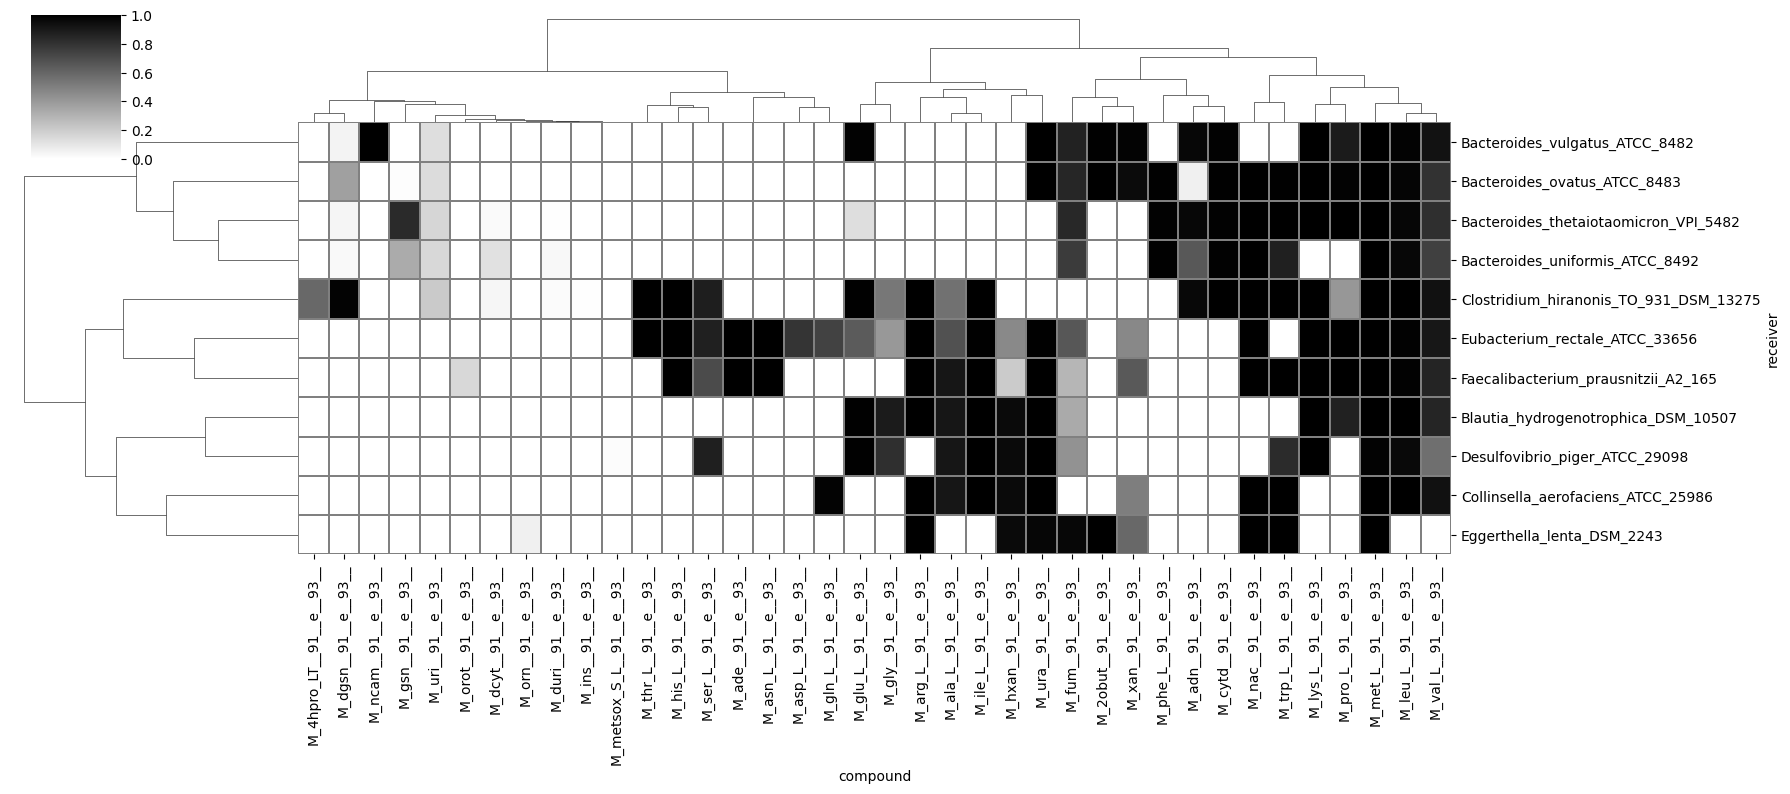

In [21]:
results_env = results[(results.donor=="environment")]
results_env = results_env[["receiver","compound","frequency"]]
# Find mean of frequencies
results_grouped_rec_env = results_env[(results_env.compound.isin(metid2metname.keys()))].groupby(["receiver","compound"]).mean()
sns.clustermap(results_grouped_rec_env["frequency"].unstack().fillna(0),
               cmap="binary",
               method="ward",
               vmin=0,
               figsize=(18,8),
               linewidths=0.005,
               linecolor="grey")

**Average across all solutions: donor!=environment**

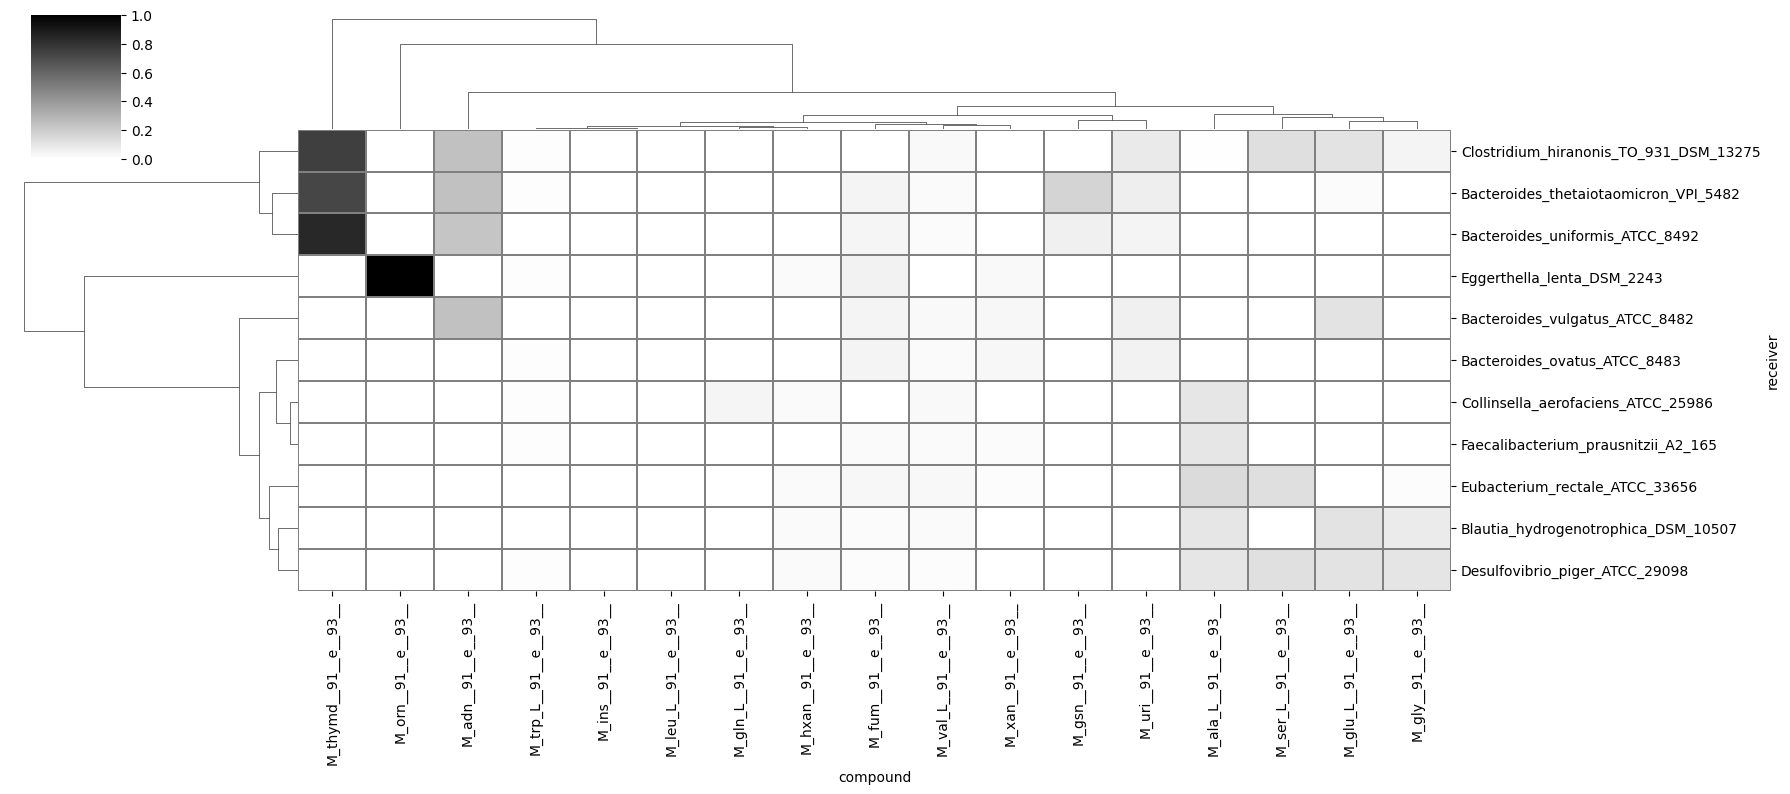

In [22]:
results_env = results[(results.donor!="environment") & (results.receiver!="environment")]
results_env = results_env[["receiver","compound","frequency"]]

results_grouped_rec_env = results_env[(results_env.compound.isin(metid2metname.keys()))].groupby(["receiver","compound"]).mean()
sns.clustermap(results_grouped_rec_env["frequency"].unstack().fillna(0),
               cmap="binary",
               method="ward",
               vmin=0,
               figsize=(18,8),
               linewidths=0.005,
               linecolor="grey")

**Average across all solutions: donor==environment|member**

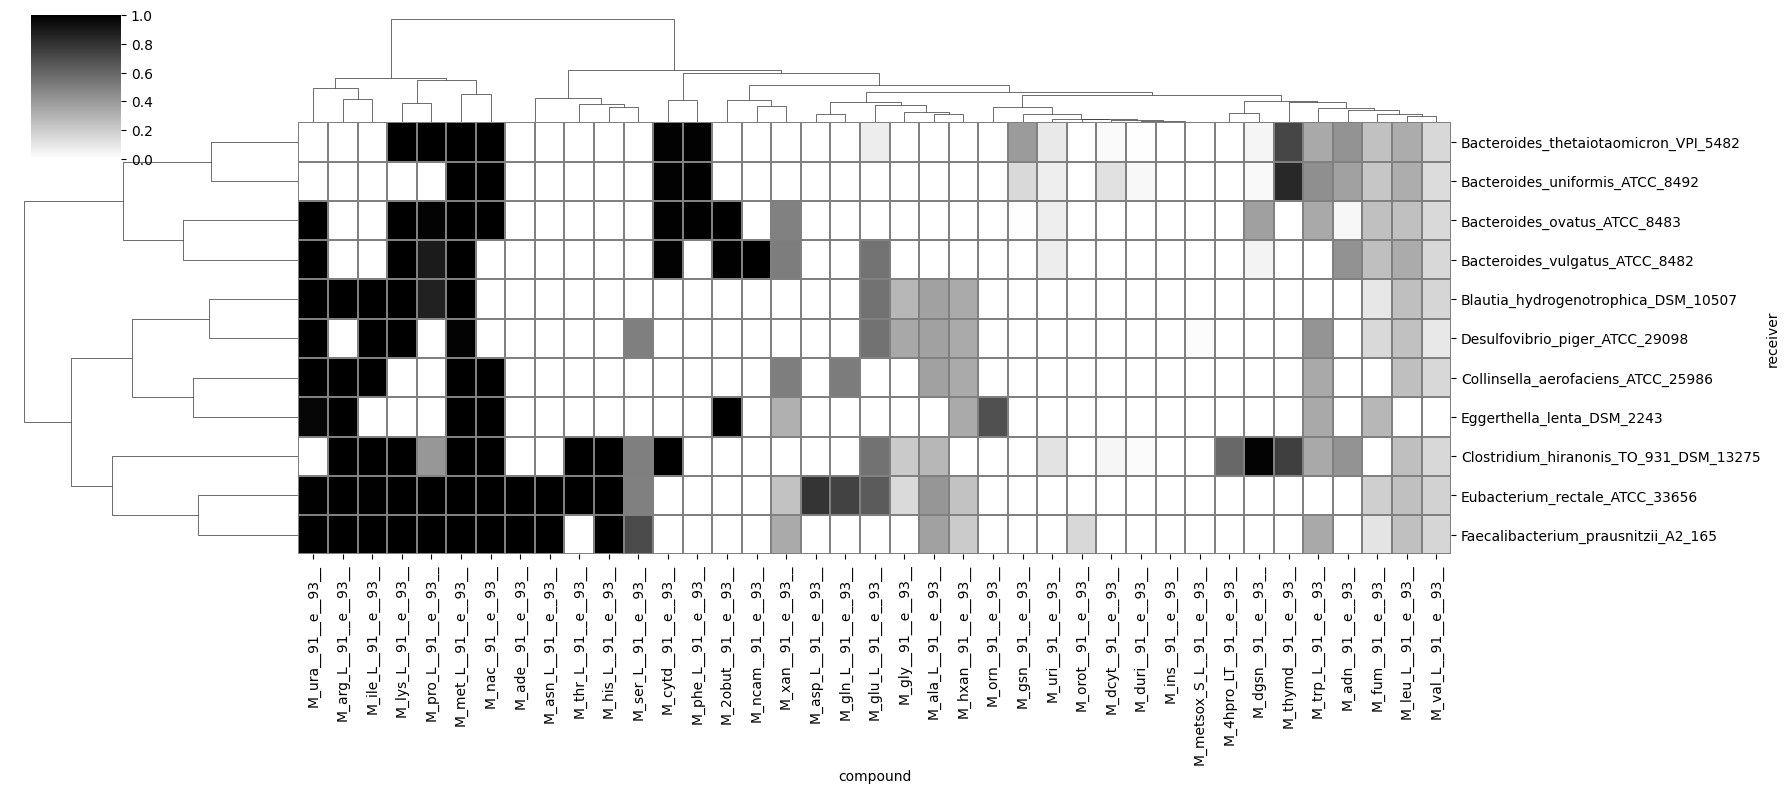

In [23]:
results_env = results[(results.receiver!="environment")]
results_env = results_env[["receiver","compound","frequency"]]

results_grouped_rec_env = results_env[(results_env.compound.isin(metid2metname.keys()))].groupby(["receiver","compound"]).mean()
sns.clustermap(results_grouped_rec_env["frequency"].unstack().fillna(0),
               cmap="binary",
               method="ward",
               vmin=0,
               figsize=(18,8),
               linewidths=0.005,
               linecolor="grey",
              )

#### Sum (but average across communities)

Here we find the sum of the frequencies. This is because one member may have different sources of the same compound.

**Sum (with average across communities) - donor!=environment & receiver!=environment**

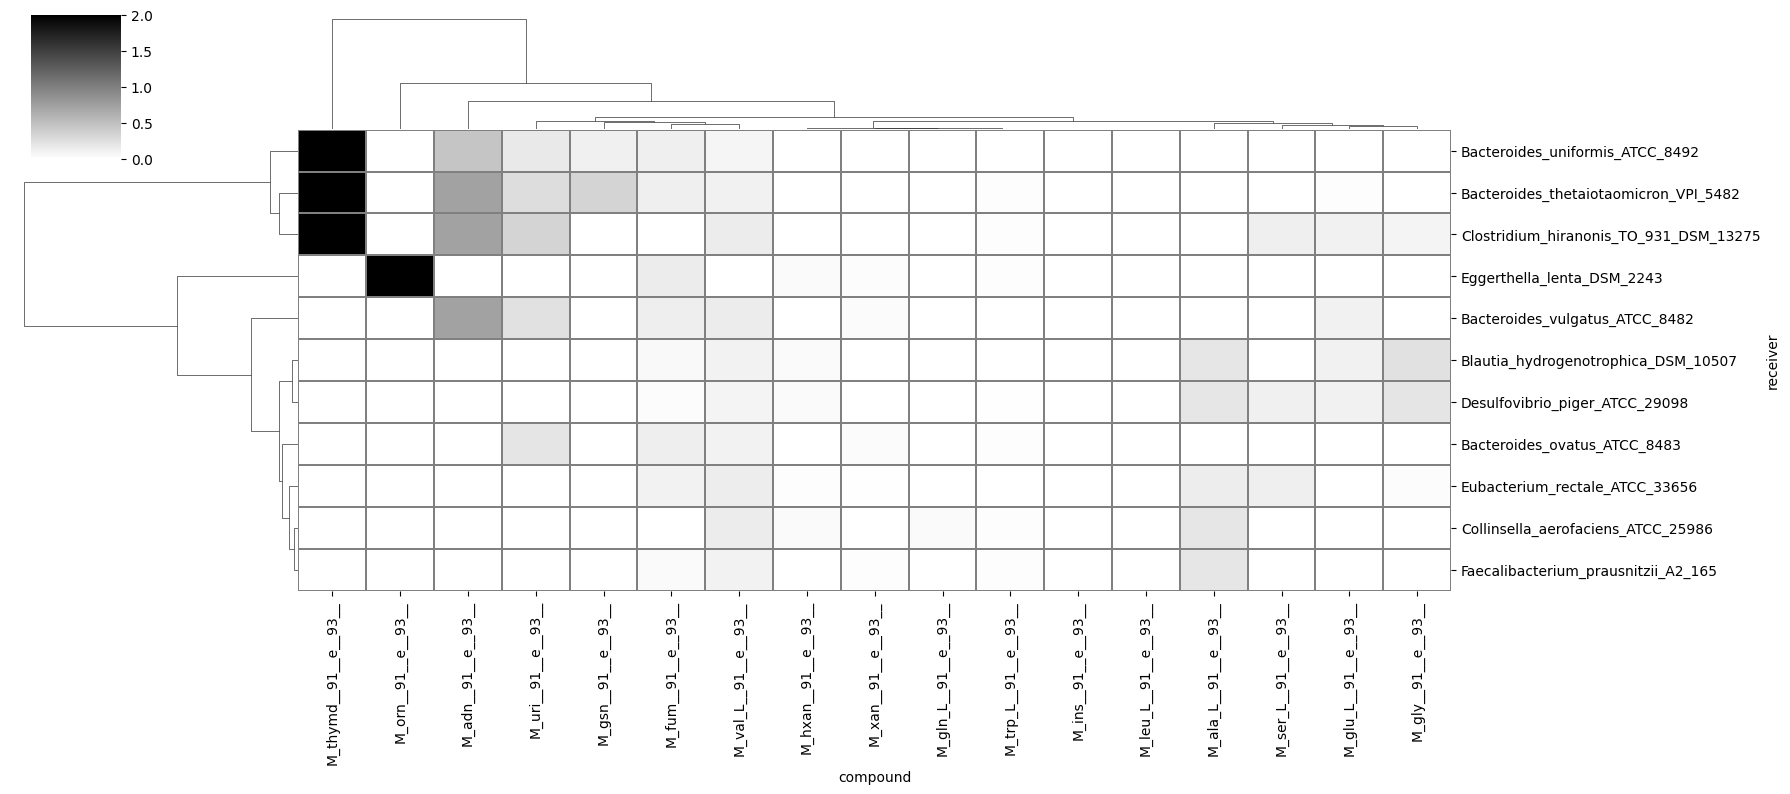

In [24]:
results_mean_freq = results[(results.receiver!="environment") & (results.donor!="environment")]
results_mean_freq = results_mean_freq[(results_mean_freq.compound.isin(metid2metname.keys()))]

# Get average frequency across all communities
results_mean_freq = results_mean_freq[["receiver","donor","compound","frequency"]].groupby(["receiver","donor","compound"]).mean()
results_mean_freq = results_mean_freq.reset_index()

# Sum up the contribution from each member
results_mean_freq = results_mean_freq[["receiver","compound","frequency"]].groupby(["receiver","compound"]).sum()

sns.clustermap(results_mean_freq["frequency"].unstack().fillna(0),
               cmap="binary",
               method="ward",
               vmin=0,
               vmax=2,
               figsize=(18,8),
               linewidths=0.005,
               linecolor="grey")

**Sum (with average across communities) - donor=environment|othermember**

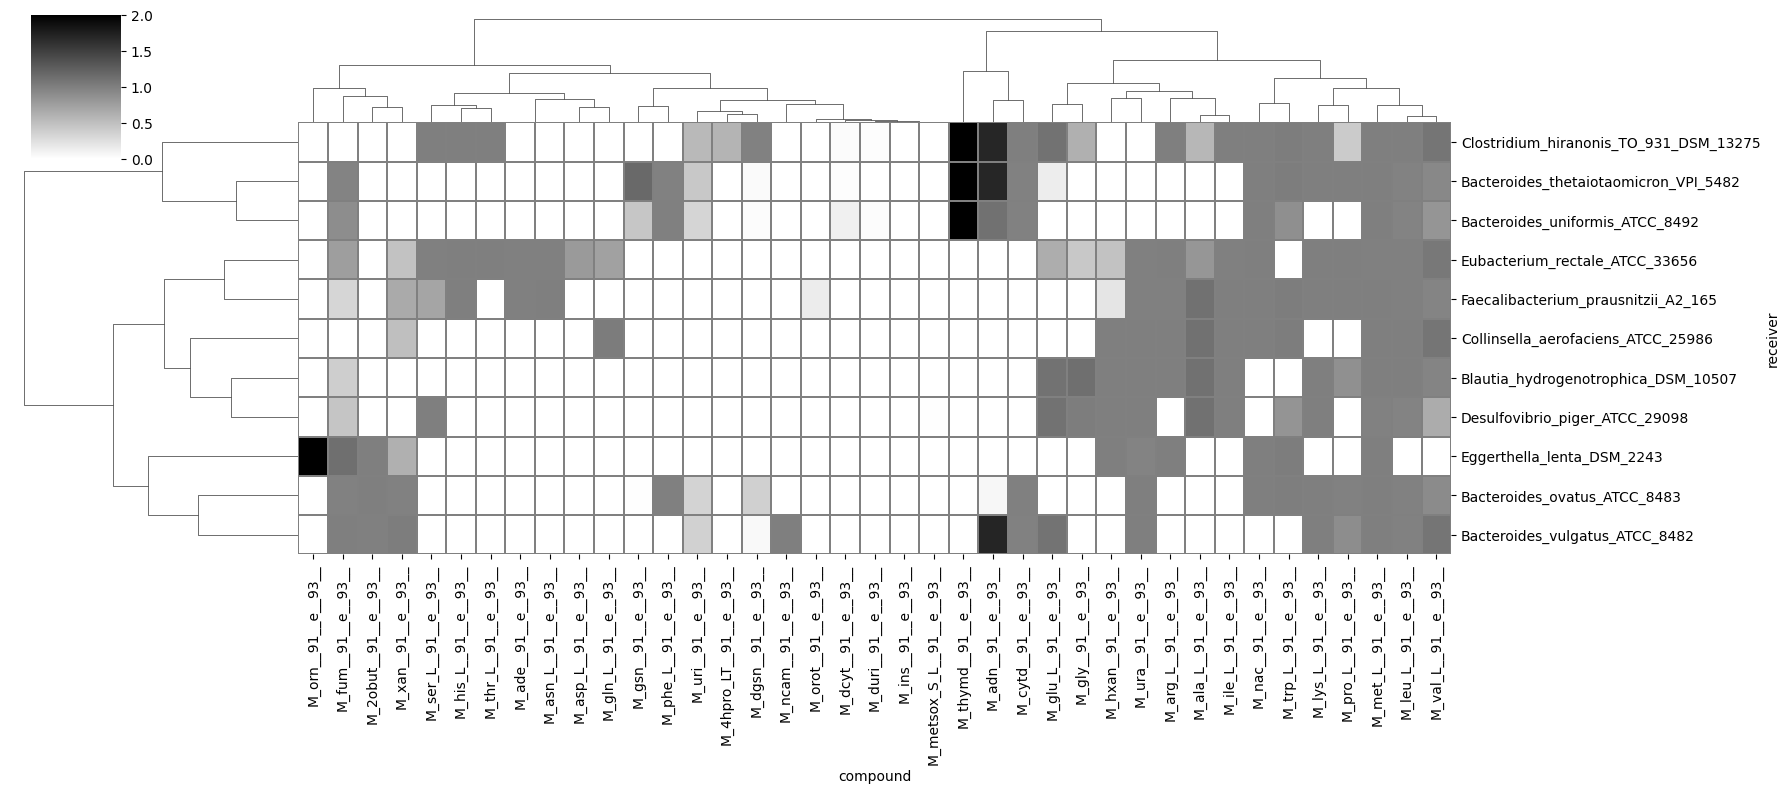

In [25]:
results_mean_freq = results[(results.receiver!="environment")]
results_mean_freq = results_mean_freq[(results_mean_freq.compound.isin(metid2metname.keys()))]

# Get average frequency across all communities
results_mean_freq = results_mean_freq[["receiver","donor","compound","frequency"]].groupby(["receiver","donor","compound"]).mean()
results_mean_freq = results_mean_freq.reset_index()



# Sum up the contribution from each member
results_mean_freq = results_mean_freq[["receiver","compound","frequency"]].groupby(["receiver","compound"]).sum()
sns.clustermap(results_mean_freq["frequency"].unstack().fillna(0),
               cmap="binary",
               method="ward",
               vmin=0,
               vmax=2,
               figsize=(18,8),
               linewidths=0.005,
               linecolor="grey")